In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import os
os.chdir('/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO')
print(os.getcwd())


/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO


In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import files

In [21]:
notebook_path = '/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO/images/notebook.jpg'
mask_path = '/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO/images/notebook_mask.png'
coins_path = '/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO/images/coins.jpg'
tomatoes_path = '/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO/images/tomatoes2.jpg'
rock_path = '/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO/images/rock.jpg'

In [12]:
def img_read(path, gray=True):
  if gray:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
  else:
    img = cv2.imread(path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  return img




**Task 1. Thresholding, honestly evaluated**

In [ ]:
##############################################
# Global Threshold
##############################################
def global_threshold(image, thresh=127):
    _, mask = cv2.threshold(image, thresh, 255, cv2.THRESH_BINARY)
    return mask

##############################################
# Otsu's Method
##############################################
def otsu_threshold(image):
    _, mask = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return mask


##############################################
# Adaptive Thresholding
##############################################
def adaptive_mean(image, ksize=21, C=5):
    return cv2.adaptiveThreshold(image, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                 cv2.THRESH_BINARY, ksize, C)

def adaptive_gaussian(image, ksize=21, C=5):
    return cv2.adaptiveThreshold(image, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, ksize, C)

##############################################
# Intersection Over Union
##############################################

def iou(pred_mask, ref_mask):
    pred_bin = pred_mask > 0
    ref_bin = ref_mask > 0
    intersection = np.logical_and(pred_bin, ref_bin).sum()
    union = np.logical_or(pred_bin, ref_bin).sum()
    return intersection / union if union > 0 else 0


Global IoU: 0.020
Otsu IoU: 0.031
Adaptive Mean IoU: 0.029
Adaptive Gaussian IoU: 0.041


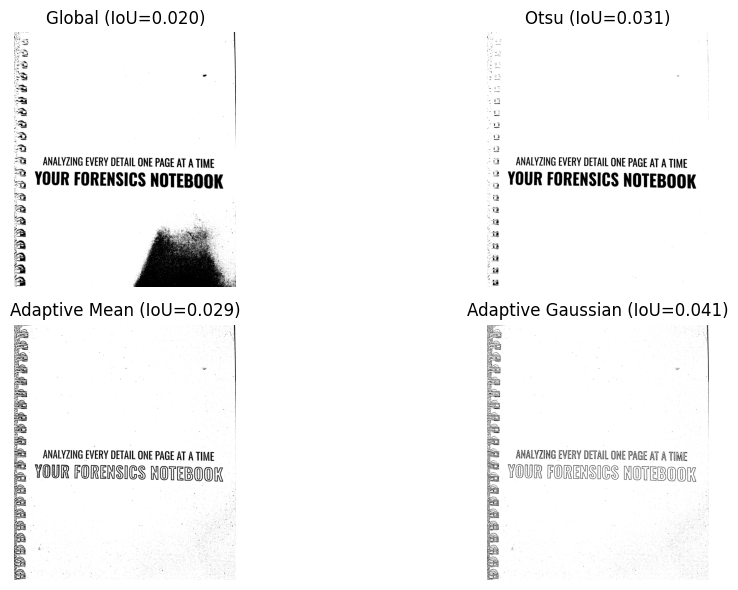

In [ ]:
##############################################
# IoU Report
##############################################
methods = {
    "Global": global_threshold(image=img_read(notebook_path)),
    "Otsu": otsu_threshold(image=img_read(notebook_path)),
    "Adaptive Mean": adaptive_mean(image=img_read(notebook_path)),
    "Adaptive Gaussian": adaptive_gaussian(image=img_read(notebook_path))
}

# --- Compute IoU scores ---
scores = {name: iou(mask, ref_mask=img_read(mask_path)) for name, mask in methods.items()}

# --- Print results ---
for name, score in scores.items():
    print(f"{name} IoU: {score:.3f}")

# --- Visualize masks side by side ---
plt.figure(figsize=(12,6))
for i, (name, mask) in enumerate(methods.items(), 1):
    plt.subplot(2,2,i)
    plt.imshow(mask, cmap="gray")
    plt.title(f"{name} (IoU={scores[name]:.3f})")
    plt.axis("off")
plt.tight_layout()
plt.show()


**Task 2. Watershed for touching objects**

Watershed object count: 3


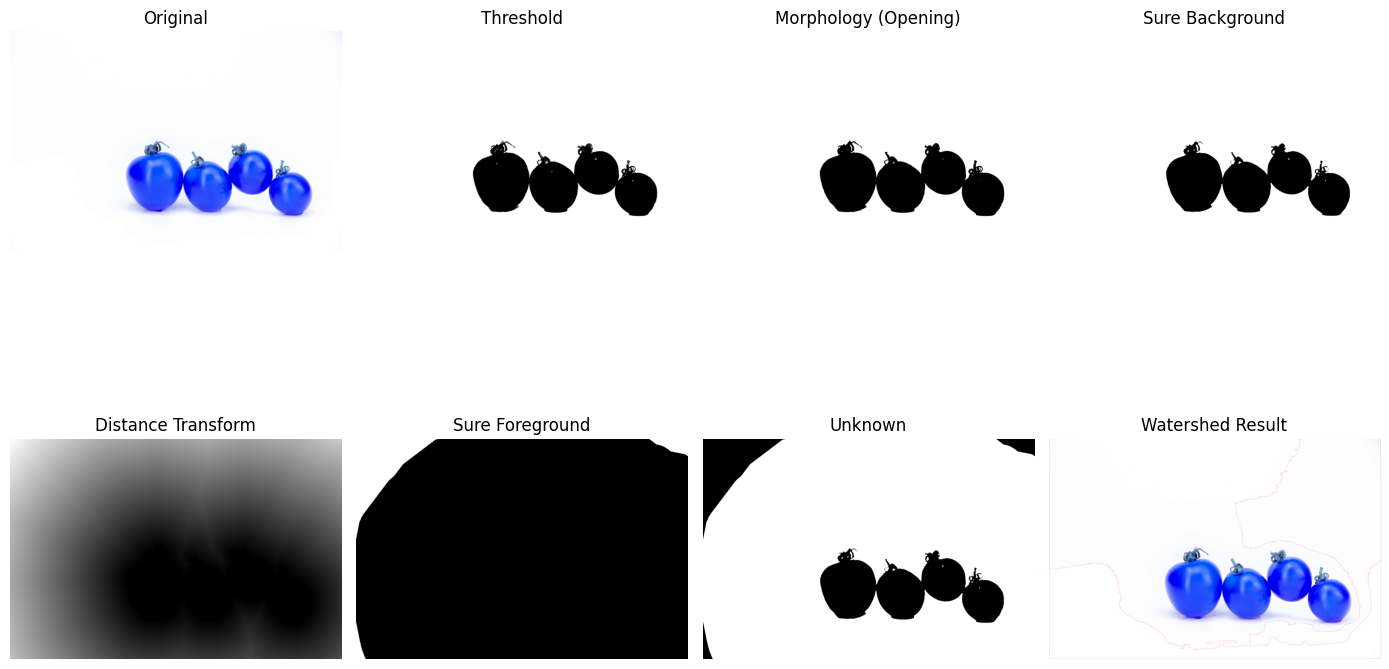

In [27]:

# --- Load grayscale image ---
gray_img = img_read(tomatoes_path)
#gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# --- Step 1: Threshold (binary image) ---
_, thresh = cv2.threshold(gray_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# --- Step 2: Morphological cleanup ---
kernel = np.ones((3,3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

# --- Step 3: Sure background (dilate) ---
sure_bg = cv2.dilate(opening, kernel, iterations=3)

# --- Step 4: Distance transform ---
dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
# Normalize for visualization
dist_norm = cv2.normalize(dist_transform, None, 0, 1.0, cv2.NORM_MINMAX)

# --- Step 5: Sure foreground (threshold distance map) ---
_, sure_fg = cv2.threshold(dist_transform, 0.7*dist_transform.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

# --- Step 6: Unknown region ---
unknown = cv2.subtract(sure_bg, sure_fg)

# --- Step 7: Marker labelling ---
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1  # ensure background is not 0 but 1
markers[unknown == 255] = 0

# --- Step 8: Watershed ---
rgb_img = img_read(tomatoes_path, gray=False)
markers = cv2.watershed(rgb_img, markers)
segmented = rgb_img.copy()
segmented[markers == -1] = [255,0,0]

# Count unique labels (excluding background and boundary)
labels = np.unique(markers)
object_count = len(labels[(labels != -1) & (labels != 1)])
print("Watershed object count:", object_count)

# --- Visualization ---
titles = ["Original", "Threshold", "Morphology (Opening)",
          "Sure Background", "Distance Transform",
          "Sure Foreground", "Unknown", "Watershed Result"]
images = [rgb_img, thresh, opening, sure_bg, dist_norm, sure_fg, unknown, segmented]

plt.figure(figsize=(14,10))
for i in range(len(images)):
    plt.subplot(2,4,i+1)
    cmap = "gray" if len(images[i].shape)==2 else None
    plt.imshow(images[i], cmap=cmap)
    plt.title(titles[i])
    plt.axis("off")
plt.tight_layout()
plt.show()
